# Day 22 — Configuration Management for Data Science
### Gerenciamento de configuração com YAML, TOML, dotenv, composição estilo Hydra e validação com Pydantic para pipelines reprodutíveis

**Fase 1 — Python Basics · Dia 22 de 28 · 21/11/2026**
Autor: Gutemberg Rapôso — Linguística + Data Science + NLP aplicado à educação

## 🎯 Objetivos de aprendizagem

Ao final deste notebook, serei capaz de:

1. Usar as abordagens nativas do Python para configuração: `configparser` (INI), `os.environ` e `argparse`.
2. Carregar segredos e parâmetros de ambiente a partir de arquivos `.env` com `python-dotenv`.
3. Escrever e ler configurações **YAML** com `yaml.safe_load()`, incluindo estruturas aninhadas, listas, âncoras (`&`) e aliases (`*`).
4. Ler **TOML** com o módulo nativo `tomllib` (Python 3.11+) e escrever com `tomli_w`.
5. Implementar um padrão leve de **composição de configuração estilo Hydra** (grupos + overrides) com `dataclasses`.
6. **Validar** configurações com Pydantic v2 e tratar erros de forma amigável.
7. Construir um pipeline de ML reprodutível no dataset *penguins* em que **mudar a configuração muda o experimento sem tocar no código**.

## 🤔 Por que gerenciamento de configuração importa?

Em projetos de Data Science, é comum ver *hiperparâmetros*, caminhos de arquivos e chaves de API espalhados pelo código ("magic numbers"). Isso gera problemas:

- **Reprodutibilidade:** se o `random_state`, o `test_size` e as features estão num arquivo de configuração versionado, qualquer pessoa consegue reproduzir o experimento exatamente.
- **Colaboração em equipe:** cientistas de dados alteram parâmetros sem editar a lógica; revisores leem um diff de YAML em vez de um diff de Python.
- **Pipelines de produção:** o mesmo código roda em `dev`, `staging` e `prod`, mudando apenas a configuração (caminhos, recursos, credenciais).
- **Segurança:** segredos ficam em variáveis de ambiente, nunca no repositório.

> Princípio central: **código = lógica; configuração = decisões**. Separar os dois é o que transforma um notebook exploratório num pipeline reprodutível.

No meu contexto (NLP aplicado ao ensino de inglês), isso significa, por exemplo, poder trocar o corpus, o limiar de frequência de vocabulário ou as faixas de nível *inspiradas* no CEFR sem reescrever funções.

In [1]:
"""Setup: imports, versions and a temporary working directory.

All config files created in this notebook live inside a TemporaryDirectory,
so nothing is left behind in the repository.
"""
import os
import sys
import json
import tempfile
import configparser
import argparse
import copy
from pathlib import Path
from dataclasses import dataclass, field, asdict
from typing import Any, Literal

import numpy as np
import pandas as pd
import seaborn as sns

print(f"Python  : {sys.version.split()[0]}")
print(f"pandas  : {pd.__version__}")
print(f"seaborn : {sns.__version__}")

TMP = tempfile.TemporaryDirectory(prefix="day22_config_")
WORKDIR = Path(TMP.name)
print(f"Temporary working dir: {WORKDIR}")

Python  : 3.11.17
pandas  : 2.3.3
seaborn : 0.13.2
Temporary working dir: /tmp/day22_config_mx_1w9dk


---
## Seção 1 — Abordagens nativas do Python

Antes de instalar qualquer biblioteca, o Python já oferece três ferramentas:

| Ferramenta | Formato | Uso típico |
|---|---|---|
| `configparser` | INI (`[seção]` + `chave = valor`) | Configurações simples, legado, ferramentas como `setup.cfg`, `pytest.ini` |
| `os.environ` | Variáveis de ambiente | Segredos, diferenças entre ambientes, contêineres |
| `argparse` | Argumentos de linha de comando | Overrides pontuais na execução (`--seed 7`) |

### 1.1 `configparser` e arquivos INI
Atenção: o INI **não tem tipos** — tudo é string. Por isso usamos `getint`, `getfloat` e `getboolean`.

In [2]:
ini_path = WORKDIR / "pipeline.ini"

config = configparser.ConfigParser()
config["DEFAULT"] = {"random_seed": "42", "verbose": "true"}
config["data"] = {
    "dataset": "tips",
    "target": "tip",
    "features": "total_bill, size",
}
config["model"] = {"type": "linear_regression", "test_size": "0.25"}

with ini_path.open("w", encoding="utf-8") as fh:
    config.write(fh)

print(ini_path.read_text(encoding="utf-8"))

[DEFAULT]
random_seed = 42
verbose = true

[data]
dataset = tips
target = tip
features = total_bill, size

[model]
type = linear_regression
test_size = 0.25




In [3]:
def read_ini(path: Path) -> dict[str, Any]:
    """Read an INI file and convert values to proper Python types.

    Args:
        path: Path to the INI file.

    Returns:
        A typed dictionary with the pipeline settings.
    """
    parser = configparser.ConfigParser()
    parser.read(path, encoding="utf-8")
    return {
        "dataset": parser.get("data", "dataset"),
        "target": parser.get("data", "target"),
        "features": [f.strip() for f in parser.get("data", "features").split(",")],
        "test_size": parser.getfloat("model", "test_size"),
        # values in [DEFAULT] are inherited by every section
        "random_seed": parser.getint("model", "random_seed"),
        "verbose": parser.getboolean("data", "verbose"),
    }

ini_cfg = read_ini(ini_path)
print(ini_cfg)
tips = sns.load_dataset(ini_cfg["dataset"])
print(tips[ini_cfg["features"] + [ini_cfg["target"]]].describe().round(2))

{'dataset': 'tips', 'target': 'tip', 'features': ['total_bill', 'size'], 'test_size': 0.25, 'random_seed': 42, 'verbose': True}
       total_bill    size     tip
count      244.00  244.00  244.00
mean        19.79    2.57    3.00
std          8.90    0.95    1.38
min          3.07    1.00    1.00
25%         13.35    2.00    2.00
50%         17.80    2.00    2.90
75%         24.13    3.00    3.56
max         50.81    6.00   10.00


### 1.2 Variáveis de ambiente com `os.environ`
Variáveis de ambiente são o mecanismo padrão para passar configuração a processos (Docker, CI, servidores). Sempre forneça um **valor padrão** e converta o tipo explicitamente.

In [4]:
def env_int(name: str, default: int) -> int:
    """Read an integer environment variable with a fallback default."""
    raw = os.environ.get(name)
    return default if raw is None else int(raw)

os.environ["DS_RANDOM_SEED"] = "123"          # simulating `export DS_RANDOM_SEED=123`
print("DS_RANDOM_SEED  ->", env_int("DS_RANDOM_SEED", 42))
print("DS_N_JOBS (unset) ->", env_int("DS_N_JOBS", 1))

# os.getenv is equivalent to os.environ.get
print("DS_ENV ->", os.getenv("DS_ENV", "dev"))
del os.environ["DS_RANDOM_SEED"]

DS_RANDOM_SEED  -> 123
DS_N_JOBS (unset) -> 1
DS_ENV -> dev


### 1.3 `argparse` (recapitulação rápida)
Já estudei `argparse` em detalhe no Dia 20. Aqui o ponto é a **ordem de precedência** típica:

`defaults no código` < `arquivo de config` < `variáveis de ambiente` < `argumentos de CLI`

In [5]:
def resolve_settings(cli_args: list[str], file_cfg: dict[str, Any]) -> dict[str, Any]:
    """Merge settings with precedence: defaults < file < env < CLI."""
    settings = {"random_seed": 0, "test_size": 0.2}             # code defaults
    settings.update({k: file_cfg[k] for k in settings if k in file_cfg})
    if "DS_TEST_SIZE" in os.environ:
        settings["test_size"] = float(os.environ["DS_TEST_SIZE"])

    parser = argparse.ArgumentParser(prog="pipeline")
    parser.add_argument("--random-seed", type=int)
    parser.add_argument("--test-size", type=float)
    args = parser.parse_args(cli_args)
    for key, value in vars(args).items():
        if value is not None:
            settings[key] = value
    return settings

os.environ["DS_TEST_SIZE"] = "0.3"
print(resolve_settings([], ini_cfg))                       # file + env
print(resolve_settings(["--random-seed", "7"], ini_cfg))   # CLI wins for the seed
del os.environ["DS_TEST_SIZE"]

{'random_seed': 42, 'test_size': 0.3}
{'random_seed': 7, 'test_size': 0.3}


---
## Seção 2 — Arquivos `.env` com `python-dotenv`

Um arquivo `.env` é uma lista de `CHAVE=valor` carregada para `os.environ`. É ideal para **segredos** (tokens de API, senhas de banco) e para parâmetros que mudam por máquina.

Instalação: `pip install python-dotenv`

In [6]:
import importlib.util
import subprocess

for pkg, module in [("python-dotenv", "dotenv"), ("PyYAML", "yaml"),
                    ("tomli-w", "tomli_w"), ("pydantic", "pydantic")]:
    if importlib.util.find_spec(module) is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=True)
    print(f"{pkg:<14} available")

from dotenv import load_dotenv, dotenv_values

python-dotenv  available
PyYAML         available
tomli-w        available
pydantic       available


In [7]:
env_path = WORKDIR / ".env"
env_path.write_text(
    """# Local settings for the DS pipeline - NEVER commit this file
DS_ENV=dev
DATASET_NAME=titanic
TARGET_COLUMN=survived
RANDOM_SEED=42
TEST_SIZE=0.25
MAX_DEPTH=4
# a fake placeholder secret used only to demonstrate masking
API_TOKEN=replace-me-locally
""",
    encoding="utf-8",
)

# dotenv_values parses the file WITHOUT touching os.environ
print(dotenv_values(env_path))

loaded = load_dotenv(env_path, override=True)
print("\nload_dotenv returned:", loaded)
print("DATASET_NAME =", os.getenv("DATASET_NAME"))
print("RANDOM_SEED  =", int(os.getenv("RANDOM_SEED")))

OrderedDict([('DS_ENV', 'dev'), ('DATASET_NAME', 'titanic'), ('TARGET_COLUMN', 'survived'), ('RANDOM_SEED', '42'), ('TEST_SIZE', '0.25'), ('MAX_DEPTH', '4'), ('API_TOKEN', 'replace-me-locally')])

load_dotenv returned: True
DATASET_NAME = titanic
RANDOM_SEED  = 42


### Boas práticas com `.env`
- **Nunca** versione o `.env`: adicione `.env` ao `.gitignore`.
- Versione um **`.env.example`** com as chaves, mas com valores vazios ou fictícios — ele documenta o que é necessário.
- Converta tipos explicitamente (`int()`, `float()`); tudo chega como string.
- Ao imprimir configurações em logs, **mascare segredos**.

In [8]:
example_path = WORKDIR / ".env.example"
keys = list(dotenv_values(env_path).keys())
example_path.write_text("\n".join(f"{k}=" for k in keys) + "\n", encoding="utf-8")
print(".env.example:\n" + example_path.read_text(encoding="utf-8"))

gitignore = WORKDIR / ".gitignore"
gitignore.write_text(".env\n*.env.local\n", encoding="utf-8")
print(".gitignore:\n" + gitignore.read_text(encoding="utf-8"))

def masked(cfg: dict[str, str], secret_markers=("TOKEN", "KEY", "PASSWORD")) -> dict[str, str]:
    """Return a copy of cfg with secret-looking values masked for logging."""
    return {k: ("***" if any(m in k for m in secret_markers) else v) for k, v in cfg.items()}

print(masked(dotenv_values(env_path)))

.env.example:
DS_ENV=
DATASET_NAME=
TARGET_COLUMN=
RANDOM_SEED=
TEST_SIZE=
MAX_DEPTH=
API_TOKEN=

.gitignore:
.env
*.env.local

{'DS_ENV': 'dev', 'DATASET_NAME': 'titanic', 'TARGET_COLUMN': 'survived', 'RANDOM_SEED': '42', 'TEST_SIZE': '0.25', 'MAX_DEPTH': '4', 'API_TOKEN': '***'}


In [9]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

# A .env-driven pipeline: every decision comes from environment variables
dataset = sns.load_dataset(os.environ["DATASET_NAME"])
target = os.environ["TARGET_COLUMN"]
seed = int(os.environ["RANDOM_SEED"])

features = ["pclass", "age", "sibsp", "parch", "fare"]
df = dataset[features + [target]].dropna()
X_tr, X_te, y_tr, y_te = train_test_split(
    df[features], df[target],
    test_size=float(os.environ["TEST_SIZE"]), random_state=seed, stratify=df[target],
)
clf = DecisionTreeClassifier(max_depth=int(os.environ["MAX_DEPTH"]), random_state=seed)
clf.fit(X_tr, y_tr)
print(f"Rows used: {len(df)} | test accuracy (single split): {accuracy_score(y_te, clf.predict(X_te)):.3f}")

Rows used: 714 | test accuracy (single split): 0.665


---
## Seção 3 — Configuração com YAML

YAML é o formato mais popular para configs de ML (Hydra, MLflow, DVC, GitHub Actions, Kubernetes). Vantagens: legível, aceita **comentários**, estruturas aninhadas e tipos nativos (int, float, bool, listas, null).

⚠️ **Sempre use `yaml.safe_load()`**, nunca `yaml.load()` sem `Loader` seguro: YAML pode instanciar objetos Python arbitrários, o que é uma falha de segurança.

In [10]:
import yaml

tips_yaml = """
# Pipeline config for the seaborn 'tips' dataset
project:
  name: tips-analysis
  version: 1.0.0

dataset:
  name: tips
  target: tip
  numeric_features: [total_bill, size]
  categorical_features:
    - sex
    - smoker
    - day
    - time

preprocessing:
  dropna: true
  scale_numeric: true
  one_hot: true

model:
  type: ridge
  hyperparams:
    alpha: 1.0
  test_size: 0.2
  random_state: 42

output:
  dir: outputs/tips
  save_predictions: false
  metrics: [r2, mae]
"""

yaml_path = WORKDIR / "tips_config.yaml"
yaml_path.write_text(tips_yaml, encoding="utf-8")

with yaml_path.open(encoding="utf-8") as fh:
    tips_cfg = yaml.safe_load(fh)

print(type(tips_cfg))
print(json.dumps(tips_cfg, indent=2))

<class 'dict'>
{
  "project": {
    "name": "tips-analysis",
    "version": "1.0.0"
  },
  "dataset": {
    "name": "tips",
    "target": "tip",
    "numeric_features": [
      "total_bill",
      "size"
    ],
    "categorical_features": [
      "sex",
      "smoker",
      "day",
      "time"
    ]
  },
  "preprocessing": {
    "dropna": true,
    "scale_numeric": true,
    "one_hot": true
  },
  "model": {
    "type": "ridge",
    "hyperparams": {
      "alpha": 1.0
    },
    "test_size": 0.2,
    "random_state": 42
  },
  "output": {
    "dir": "outputs/tips",
    "save_predictions": false,
    "metrics": [
      "r2",
      "mae"
    ]
  }
}


In [11]:
# YAML gives native types: no manual conversion needed (unlike INI/.env)
for key_path in [("model", "test_size"), ("model", "random_state"),
                 ("preprocessing", "dropna"), ("dataset", "categorical_features")]:
    value = tips_cfg[key_path[0]][key_path[1]]
    print(f"{'.'.join(key_path):<32} {value!r:<40} {type(value).__name__}")

model.test_size                  0.2                                      float
model.random_state               42                                       int
preprocessing.dropna             True                                     bool
dataset.categorical_features     ['sex', 'smoker', 'day', 'time']         list


### Âncoras (`&`) e aliases (`*`)
Âncoras evitam repetição: definimos um bloco uma vez e o reutilizamos. A chave de *merge* `<<:` permite herdar um bloco e sobrescrever campos — útil para vários experimentos que compartilham defaults.

In [12]:
anchors_yaml = """
defaults: &model_defaults
  random_state: 42
  test_size: 0.2
  cv_folds: 5

experiments:
  baseline:
    <<: *model_defaults
    model: ridge
    alpha: 1.0
  strong_regularization:
    <<: *model_defaults
    model: ridge
    alpha: 50.0
  small_test:
    <<: *model_defaults
    model: ridge
    alpha: 1.0
    test_size: 0.1          # overrides the anchored value

shared_feature_list: &feats [total_bill, size]
reports:
  correlation_features: *feats
"""
anchors_path = WORKDIR / "experiments.yaml"
anchors_path.write_text(anchors_yaml, encoding="utf-8")
exp_cfg = yaml.safe_load(anchors_path.read_text(encoding="utf-8"))

print(pd.DataFrame(exp_cfg["experiments"]).T)
print("\nAlias resolved:", exp_cfg["reports"]["correlation_features"])

                      random_state test_size cv_folds  model alpha
baseline                        42       0.2        5  ridge   1.0
strong_regularization           42       0.2        5  ridge  50.0
small_test                      42       0.1        5  ridge   1.0

Alias resolved: ['total_bill', 'size']


In [13]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import Ridge
from sklearn.metrics import r2_score, mean_absolute_error


def run_tips_experiment(cfg: dict[str, Any], alpha: float | None = None,
                        test_size: float | None = None) -> dict[str, float]:
    """Train a Ridge regression on seaborn 'tips' driven entirely by a YAML config."""
    ds = cfg["dataset"]
    data = sns.load_dataset(ds["name"])
    if cfg["preprocessing"]["dropna"]:
        data = data.dropna()
    X = data[ds["numeric_features"] + ds["categorical_features"]]
    y = data[ds["target"]]

    transformers = []
    num_step = StandardScaler() if cfg["preprocessing"]["scale_numeric"] else "passthrough"
    transformers.append(("num", num_step, ds["numeric_features"]))
    if cfg["preprocessing"]["one_hot"]:
        transformers.append(("cat", OneHotEncoder(handle_unknown="ignore"), ds["categorical_features"]))

    model_cfg = cfg["model"]
    pipe = Pipeline([
        ("prep", ColumnTransformer(transformers, remainder="drop")),
        ("model", Ridge(alpha=alpha if alpha is not None else model_cfg["hyperparams"]["alpha"])),
    ])
    X_tr, X_te, y_tr, y_te = train_test_split(
        X, y, test_size=test_size or model_cfg["test_size"], random_state=model_cfg["random_state"])
    pipe.fit(X_tr, y_tr)
    pred = pipe.predict(X_te)
    metric_fns = {"r2": r2_score, "mae": mean_absolute_error}
    return {m: round(metric_fns[m](y_te, pred), 4) for m in cfg["output"]["metrics"]}

print("Base config:", run_tips_experiment(tips_cfg))
for name, exp in exp_cfg["experiments"].items():
    print(f"{name:<24}", run_tips_experiment(tips_cfg, alpha=exp["alpha"], test_size=exp["test_size"]))

Base config: {'r2': 0.4387, 'mae': 0.667}
baseline                 {'r2': 0.4387, 'mae': 0.667}
strong_regularization    {'r2': 0.4577, 'mae': 0.679}
small_test               {'r2': 0.3418, 'mae': 0.668}


In [14]:
# Round-trip: modify the config in memory and dump it back to YAML (sort_keys=False keeps order)
tips_cfg_v2 = copy.deepcopy(tips_cfg)
tips_cfg_v2["project"]["version"] = "1.1.0"
tips_cfg_v2["model"]["hyperparams"]["alpha"] = 10.0

v2_path = WORKDIR / "tips_config_v2.yaml"
with v2_path.open("w", encoding="utf-8") as fh:
    yaml.safe_dump(tips_cfg_v2, fh, sort_keys=False, allow_unicode=True)
print(v2_path.read_text(encoding="utf-8")[:400])
print("v2 metrics:", run_tips_experiment(yaml.safe_load(v2_path.read_text(encoding="utf-8"))))

project:
  name: tips-analysis
  version: 1.1.0
dataset:
  name: tips
  target: tip
  numeric_features:
  - total_bill
  - size
  categorical_features:
  - sex
  - smoker
  - day
  - time
preprocessing:
  dropna: true
  scale_numeric: true
  one_hot: true
model:
  type: ridge
  hyperparams:
    alpha: 10.0
  test_size: 0.2
  random_state: 42
output:
  dir: outputs/tips
  save_predictions: false
  
v2 metrics: {'r2': 0.4478, 'mae': 0.6657}


> 📝 Observação: `safe_dump` **remove comentários** — o YAML gerado por código perde a documentação. Configurações "fonte da verdade" devem ser editadas por humanos; arquivos gerados servem como *snapshot* do experimento.

---
## Seção 4 — Configuração com TOML

TOML (*Tom's Obvious, Minimal Language*) é o formato do `pyproject.toml`. Desde o Python 3.11, o módulo **`tomllib`** faz parte da biblioteca padrão, mas é **somente leitura**. Para escrever, usamos `tomli_w`.

Características: tipagem explícita e sem ambiguidades, datas nativas, tabelas `[secao]` e arrays de tabelas `[[item]]`.

Vamos criar uma config para um **pipeline de NLP educacional**: corpus, tokenização e faixas de vocabulário *inspiradas* no CEFR (derivadas da frequência no próprio corpus — **não** são níveis oficiais do CEFR).

In [15]:
import tomllib
import tomli_w

nlp_toml = """
# NLP pipeline config - vocabulary profiling for English learners
title = "Brown Corpus vocabulary profiler"
created = 2026-11-21

[corpus]
name = "brown"
categories = ["news", "editorial", "learned", "fiction"]
max_tokens_per_category = 50000

[tokenization]
lowercase = true
alphabetic_only = true
min_token_length = 2
stopwords = ["the", "of", "and", "to", "a", "in", "is", "that", "it", "was"]

# Frequency-rank thresholds (CEFR-inspired bands, NOT official CEFR levels).
# A word whose rank in the full corpus is <= max_rank falls into that band.
[[bands]]
label = "A-like (very frequent)"
max_rank = 1000

[[bands]]
label = "B-like (frequent)"
max_rank = 4000

[[bands]]
label = "C-like (less frequent)"
max_rank = 1000000
"""

toml_path = WORKDIR / "nlp_config.toml"
toml_path.write_text(nlp_toml, encoding="utf-8")

with toml_path.open("rb") as fh:          # tomllib requires binary mode
    nlp_cfg = tomllib.load(fh)

print(type(nlp_cfg["created"]), nlp_cfg["created"])
print(json.dumps({k: v for k, v in nlp_cfg.items() if k != "created"}, indent=2))

<class 'datetime.date'> 2026-11-21
{
  "title": "Brown Corpus vocabulary profiler",
  "corpus": {
    "name": "brown",
    "categories": [
      "news",
      "editorial",
      "learned",
      "fiction"
    ],
    "max_tokens_per_category": 50000
  },
  "tokenization": {
    "lowercase": true,
    "alphabetic_only": true,
    "min_token_length": 2,
    "stopwords": [
      "the",
      "of",
      "and",
      "to",
      "a",
      "in",
      "is",
      "that",
      "it",
      "was"
    ]
  },
  "bands": [
    {
      "label": "A-like (very frequent)",
      "max_rank": 1000
    },
    {
      "label": "B-like (frequent)",
      "max_rank": 4000
    },
    {
      "label": "C-like (less frequent)",
      "max_rank": 1000000
    }
  ]
}


In [16]:
import nltk
from collections import Counter

nltk.download("brown", quiet=True)
from nltk.corpus import brown


def tokenize(words: list[str], tok_cfg: dict[str, Any]) -> list[str]:
    """Normalize and filter tokens according to the [tokenization] config table."""
    stop = set(tok_cfg["stopwords"])
    out = []
    for w in words:
        if tok_cfg["lowercase"]:
            w = w.lower()
        if tok_cfg["alphabetic_only"] and not w.isalpha():
            continue
        if len(w) < tok_cfg["min_token_length"] or w in stop:
            continue
        out.append(w)
    return out


corpus_cfg, tok_cfg = nlp_cfg["corpus"], nlp_cfg["tokenization"]
tokens_by_cat = {
    cat: tokenize(list(brown.words(categories=cat))[: corpus_cfg["max_tokens_per_category"]], tok_cfg)
    for cat in corpus_cfg["categories"]
}
all_counts = Counter(t for toks in tokens_by_cat.values() for t in toks)
rank = {w: i + 1 for i, (w, _) in enumerate(all_counts.most_common())}
print(f"Vocabulary size across selected categories: {len(rank):,}")
print("Top 10:", [w for w, _ in all_counts.most_common(10)])

Vocabulary size across selected categories: 16,632
Top 10: ['for', 'he', 'be', 'with', 'on', 'his', 'as', 'by', 'at', 'this']


In [17]:
def band_of(word: str, bands: list[dict[str, Any]]) -> str:
    """Return the first band whose max_rank covers the word's frequency rank."""
    r = rank[word]
    for band in bands:
        if r <= band["max_rank"]:
            return band["label"]
    return "unbanded"

rows = []
for cat, toks in tokens_by_cat.items():
    bands = Counter(band_of(t, nlp_cfg["bands"]) for t in toks)
    total = sum(bands.values())
    row = {"category": cat, "tokens": total, "types": len(set(toks))}
    row.update({b["label"]: round(100 * bands[b["label"]] / total, 1) for b in nlp_cfg["bands"]})
    rows.append(row)

profile = pd.DataFrame(rows).set_index("category")
print("Token share (%) per frequency band — derived from this corpus sample:")
profile

Token share (%) per frequency band — derived from this corpus sample:


,tokens,types,A-like (very frequent),B-like (frequent),C-like (less frequent)
category,,,,,
news,31383,7055,59.6,22.9,17.5
editorial,32080,7187,62.8,21.0,16.2
learned,30862,5486,59.9,24.5,15.6
fiction,31615,6809,62.8,18.9,18.3


In [18]:
# Writing TOML with tomli_w: create a stricter variant of the config
strict_cfg = copy.deepcopy(nlp_cfg)
strict_cfg["title"] = "Brown profiler - strict A-like band"
strict_cfg["bands"][0]["max_rank"] = 500

strict_path = WORKDIR / "nlp_config_strict.toml"
with strict_path.open("wb") as fh:        # tomli_w also works in binary mode
    tomli_w.dump(strict_cfg, fh)

print(strict_path.read_text(encoding="utf-8")[:500])
reloaded = tomllib.loads(strict_path.read_text(encoding="utf-8"))
print("Reloaded A-like max_rank:", reloaded["bands"][0]["max_rank"])

title = "Brown profiler - strict A-like band"
created = 2026-11-21
bands = [
    { label = "A-like (very frequent)", max_rank = 500 },
    { label = "B-like (frequent)", max_rank = 4000 },
    { label = "C-like (less frequent)", max_rank = 1000000 },
]

[corpus]
name = "brown"
categories = [
    "news",
    "editorial",
    "learned",
    "fiction",
]
max_tokens_per_category = 50000

[tokenization]
lowercase = true
alphabetic_only = true
min_token_length = 2
stopwords = [
    "the",
    "of",
  
Reloaded A-like max_rank: 500


### YAML vs TOML: quando usar cada um?

| Critério | YAML | TOML |
|---|---|---|
| Leitura nativa no Python | ❌ (precisa PyYAML) | ✅ `tomllib` (3.11+) |
| Escrita | `yaml.safe_dump` | `tomli_w` (externa) |
| Aninhamento profundo | ✅ natural por indentação | ⚠️ verboso (`[a.b.c]`) |
| Ambiguidade de tipos | ⚠️ `no` → `False`, `1.10` → `1.1` | ✅ tipagem explícita |
| Âncoras/reuso | ✅ `&` / `*` | ❌ |
| Datas nativas | parcial | ✅ |
| Ecossistema | Hydra, MLflow, DVC, CI, Kubernetes | `pyproject.toml`, ruff, black, pytest |

**Regra prática:** TOML para metadados e ferramentas de projeto (configs planas e explícitas); YAML para experimentos de ML com hierarquias profundas e reuso de blocos.

In [19]:
# The classic YAML type-ambiguity pitfall ("the Norway problem")
ambiguous = yaml.safe_load("country: NO\nversion: 1.10\nanswer: yes")
print("YAML :", ambiguous)
explicit = tomllib.loads('country = "NO"\nversion = "1.10"\nanswer = true')
print("TOML :", explicit)

YAML : {'country': False, 'version': 1.1, 'answer': True}
TOML : {'country': 'NO', 'version': '1.10', 'answer': True}


---
## Seção 5 — Composição de configuração estilo Hydra (sem instalar Hydra)

O [Hydra](https://hydra.cc) organiza configs em **grupos** (`data/`, `model/`, `training/`), compõe uma config final a partir de escolhas (`model=logreg`) e aceita **overrides** na linha de comando (`model.C=0.5`). Vamos reproduzir a ideia central com `dataclasses` + YAML:

1. Arquivos YAML por grupo em diretórios separados.
2. Um `defaults` que escolhe uma opção de cada grupo.
3. *Deep merge* com overrides de experimento e overrides em notação de ponto.
4. Conversão para `dataclasses` tipadas.

In [20]:
conf_dir = WORKDIR / "conf"
group_files = {
    "data/iris.yaml": {"name": "iris", "source": "sklearn", "test_size": 0.3, "stratify": True},
    "model/logreg.yaml": {"name": "logistic_regression", "C": 1.0, "max_iter": 200},
    "model/logreg_strong_reg.yaml": {"name": "logistic_regression", "C": 0.05, "max_iter": 200},
    "training/default.yaml": {"random_state": 42, "scale_features": True, "cv_folds": 5},
    "config.yaml": {"defaults": {"data": "iris", "model": "logreg", "training": "default"},
                    "experiment_name": "iris_baseline"},
}
for rel, content in group_files.items():
    path = conf_dir / rel
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(yaml.safe_dump(content, sort_keys=False), encoding="utf-8")

for p in sorted(conf_dir.rglob("*.yaml")):
    print(p.relative_to(WORKDIR))

conf/config.yaml
conf/data/iris.yaml
conf/model/logreg.yaml
conf/model/logreg_strong_reg.yaml
conf/training/default.yaml


In [21]:
def deep_merge(base: dict, override: dict) -> dict:
    """Recursively merge `override` into a copy of `base` (override wins)."""
    merged = copy.deepcopy(base)
    for key, value in override.items():
        if isinstance(value, dict) and isinstance(merged.get(key), dict):
            merged[key] = deep_merge(merged[key], value)
        else:
            merged[key] = copy.deepcopy(value)
    return merged


def apply_dotted_overrides(cfg: dict, overrides: list[str]) -> dict:
    """Apply Hydra-like 'a.b=value' overrides; values are parsed with yaml.safe_load."""
    cfg = copy.deepcopy(cfg)
    for item in overrides:
        dotted, raw = item.split("=", 1)
        *parents, leaf = dotted.split(".")
        node = cfg
        for p in parents:
            if p not in node:
                raise KeyError(f"Unknown config key in override: {dotted}")
            node = node[p]
        node[leaf] = yaml.safe_load(raw)
    return cfg


def compose(conf_dir: Path, choices: dict[str, str] | None = None,
            overrides: list[str] | None = None) -> dict:
    """Compose a config: primary file -> chosen group files -> dotted overrides."""
    primary = yaml.safe_load((conf_dir / "config.yaml").read_text(encoding="utf-8"))
    selected = {**primary.pop("defaults"), **(choices or {})}
    cfg = dict(primary)
    for group, option in selected.items():
        group_cfg = yaml.safe_load((conf_dir / group / f"{option}.yaml").read_text(encoding="utf-8"))
        cfg = deep_merge(cfg, {group: group_cfg})
    return apply_dotted_overrides(cfg, overrides or [])

print(yaml.safe_dump(compose(conf_dir), sort_keys=False))

experiment_name: iris_baseline
data:
  name: iris
  source: sklearn
  test_size: 0.3
  stratify: true
model:
  name: logistic_regression
  C: 1.0
  max_iter: 200
training:
  random_state: 42
  scale_features: true
  cv_folds: 5



In [22]:
@dataclass(frozen=True)
class DataConfig:
    name: str
    source: str
    test_size: float
    stratify: bool = True


@dataclass(frozen=True)
class ModelConfig:
    name: str
    C: float = 1.0
    max_iter: int = 100


@dataclass(frozen=True)
class TrainingConfig:
    random_state: int = 42
    scale_features: bool = True
    cv_folds: int = 5


@dataclass(frozen=True)
class ExperimentConfig:
    experiment_name: str
    data: DataConfig
    model: ModelConfig
    training: TrainingConfig

    @classmethod
    def from_dict(cls, d: dict) -> "ExperimentConfig":
        """Build typed, immutable config objects from a composed dict."""
        return cls(
            experiment_name=d["experiment_name"],
            data=DataConfig(**d["data"]),
            model=ModelConfig(**d["model"]),
            training=TrainingConfig(**d["training"]),
        )

exp = ExperimentConfig.from_dict(compose(conf_dir))
print(exp)

ExperimentConfig(experiment_name='iris_baseline', data=DataConfig(name='iris', source='sklearn', test_size=0.3, stratify=True), model=ModelConfig(name='logistic_regression', C=1.0, max_iter=200), training=TrainingConfig(random_state=42, scale_features=True, cv_folds=5))


In [23]:
from sklearn.datasets import load_iris
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score


def run_experiment(exp: ExperimentConfig) -> dict[str, Any]:
    """Train LogisticRegression on sklearn iris using only values from `exp`."""
    X, y = load_iris(return_X_y=True)
    X_tr, X_te, y_tr, y_te = train_test_split(
        X, y, test_size=exp.data.test_size, random_state=exp.training.random_state,
        stratify=y if exp.data.stratify else None)
    steps = [("scaler", StandardScaler())] if exp.training.scale_features else []
    steps.append(("clf", LogisticRegression(C=exp.model.C, max_iter=exp.model.max_iter)))
    pipe = Pipeline(steps)
    cv = cross_val_score(pipe, X_tr, y_tr, cv=exp.training.cv_folds)
    pipe.fit(X_tr, y_tr)
    return {"experiment": exp.experiment_name, "C": exp.model.C,
            "scaled": exp.training.scale_features,
            "cv_mean": round(cv.mean(), 4), "test_acc": round(pipe.score(X_te, y_te), 4)}

runs = [
    compose(conf_dir),
    compose(conf_dir, choices={"model": "logreg_strong_reg"},
            overrides=["experiment_name=iris_strong_reg"]),
    compose(conf_dir, overrides=["experiment_name=iris_no_scaling", "training.scale_features=false"]),
    compose(conf_dir, overrides=["experiment_name=iris_C10_seed7", "model.C=10", "training.random_state=7"]),
]
pd.DataFrame([run_experiment(ExperimentConfig.from_dict(r)) for r in runs])

,experiment,C,scaled,cv_mean,test_acc
0,iris_baseline,1.00,True,0.9810,0.9111
1,iris_strong_reg,0.05,True,0.8857,0.8444
2,iris_no_scaling,1.00,False,0.9714,0.9333
3,iris_C10_seed7,10.00,True,0.9810,0.9778


> Os resultados vêm de uma única divisão treino/teste do iris (150 amostras); diferenças pequenas não devem ser lidas como um ranking de modelos. O ponto aqui é que **quatro experimentos diferentes foram gerados sem alterar uma linha da função `run_experiment`**.

In [24]:
# Safety check: a typo in an override fails loudly instead of being silently ignored
try:
    compose(conf_dir, overrides=["modle.C=3"])
except KeyError as err:
    print("Caught:", err)

# A frozen dataclass also protects the config from accidental mutation at runtime
try:
    exp.model.C = 99  # type: ignore[misc]
except Exception as err:
    print("Caught:", type(err).__name__, "-", err)

Caught: 'Unknown config key in override: modle.C'
Caught: FrozenInstanceError - cannot assign to field 'C'


---
## Seção 6 — Validação de configuração com Pydantic

`dataclasses` dão estrutura, mas **não validam** valores: `test_size=1.7` passaria sem erro. O Pydantic v2 valida tipos e restrições no carregamento (*fail fast*), antes de gastar minutos treinando um modelo com uma config inválida.

Aplicação: config de um **pipeline educacional de NLP** (nível de língua, tamanho do corpus, formato de saída).

In [25]:
from pydantic import BaseModel, Field, ValidationError, field_validator, model_validator, ConfigDict

CEFR_LEVELS = ("A1", "A2", "B1", "B2", "C1", "C2")


class CorpusSettings(BaseModel):
    model_config = ConfigDict(extra="forbid")       # unknown keys are errors (typo protection)

    name: Literal["brown", "gutenberg", "reuters"]
    categories: list[str] = Field(min_length=1)
    corpus_size: int = Field(gt=0, le=1_000_000, description="Max tokens per category")


class PipelineConfig(BaseModel):
    """Validated config for an educational NLP pipeline."""
    model_config = ConfigDict(extra="forbid")

    pipeline_name: str = Field(min_length=3, pattern=r"^[a-z0-9_]+$")
    target_level: str = Field(description="Learner level label (CEFR-style)")
    min_level: str = "A1"
    corpus: CorpusSettings
    output_format: Literal["csv", "json", "parquet"] = "csv"
    random_seed: int = Field(default=42, ge=0)

    @field_validator("target_level", "min_level")
    @classmethod
    def check_level(cls, v: str) -> str:
        v = v.upper().strip()
        if v not in CEFR_LEVELS:
            raise ValueError(f"level must be one of {CEFR_LEVELS}, got {v!r}")
        return v

    @model_validator(mode="after")
    def check_level_order(self) -> "PipelineConfig":
        if CEFR_LEVELS.index(self.min_level) > CEFR_LEVELS.index(self.target_level):
            raise ValueError("min_level cannot be above target_level")
        return self

print(json.dumps(PipelineConfig.model_json_schema()["properties"]["output_format"], indent=2))

{
  "default": "csv",
  "enum": [
    "csv",
    "json",
    "parquet"
  ],
  "title": "Output Format",
  "type": "string"
}


In [26]:
valid_yaml = """
pipeline_name: reading_profiler_b1
target_level: b1          # lower case is normalized by the validator
min_level: A2
corpus:
  name: brown
  categories: [news, editorial]
  corpus_size: 20000
output_format: json
"""
valid_path = WORKDIR / "edu_pipeline.yaml"
valid_path.write_text(valid_yaml, encoding="utf-8")

edu_cfg = PipelineConfig.model_validate(yaml.safe_load(valid_path.read_text(encoding="utf-8")))
print(edu_cfg)
print("\nNormalized target_level:", edu_cfg.target_level)

pipeline_name='reading_profiler_b1' target_level='B1' min_level='A2' corpus=CorpusSettings(name='brown', categories=['news', 'editorial'], corpus_size=20000) output_format='json' random_seed=42

Normalized target_level: B1


In [27]:
invalid_yaml = """
pipeline_name: Reading Profiler!     # spaces/uppercase break the pattern
target_level: B4                     # not a valid level
min_level: C1
corpus:
  name: wikipedia                    # not an allowed corpus
  categories: []
  corpus_size: -10
  categoires: [news]                 # typo -> extra key
output_format: xlsx
"""
invalid_path = WORKDIR / "edu_pipeline_invalid.yaml"
invalid_path.write_text(invalid_yaml, encoding="utf-8")


def load_validated(path: Path) -> PipelineConfig | None:
    """Load a YAML config and validate it, reporting all errors in a readable table."""
    try:
        return PipelineConfig.model_validate(yaml.safe_load(path.read_text(encoding="utf-8")))
    except ValidationError as exc:
        report = pd.DataFrame(
            [{"field": ".".join(map(str, e["loc"])), "error": e["msg"], "input": str(e.get("input"))[:30]}
             for e in exc.errors()])
        print(f"❌ {path.name}: {exc.error_count()} validation error(s)")
        display(report)
        return None

result = load_validated(invalid_path)
print("Returned:", result)

❌ edu_pipeline_invalid.yaml: 7 validation error(s)


,field,error,input
0,pipeline_name,String should match pattern '^[a-z0-9_]+$',Reading Profiler!
1,target_level,"Value error, level must be one of ('A1', 'A2',...",B4
2,corpus.name,"Input should be 'brown', 'gutenberg' or 'reuters'",wikipedia
3,corpus.categories,List should have at least 1 item after validat...,[]
4,corpus.corpus_size,Input should be greater than 0,-10
5,corpus.categoires,Extra inputs are not permitted,['news']
6,output_format,"Input should be 'csv', 'json' or 'parquet'",xlsx


Returned: None


In [28]:
# Using the validated config to actually run the educational pipeline
def run_edu_pipeline(cfg: PipelineConfig) -> pd.DataFrame:
    """Compute simple lexical statistics per category, driven by a validated config."""
    rows = []
    for cat in cfg.corpus.categories:
        words = [w.lower() for w in brown.words(categories=cat)[: cfg.corpus.corpus_size] if w.isalpha()]
        lengths = np.array([len(w) for w in words])
        rows.append({"category": cat, "tokens": len(words),
                     "type_token_ratio": round(len(set(words)) / len(words), 3),
                     "mean_word_length": round(lengths.mean(), 2),
                     "share_long_words_%": round(100 * (lengths >= 7).mean(), 1)})
    return pd.DataFrame(rows)

edu_result = run_edu_pipeline(edu_cfg)
out_file = WORKDIR / f"{edu_cfg.pipeline_name}.{edu_cfg.output_format}"
if edu_cfg.output_format == "json":
    edu_result.to_json(out_file, orient="records", indent=2)
else:
    edu_result.to_csv(out_file, index=False)
print(f"Saved -> {out_file.name} ({out_file.stat().st_size} bytes)")
edu_result

Saved -> reading_profiler_b1.json (289 bytes)


,category,tokens,type_token_ratio,mean_word_length,share_long_words_%
0,news,17109,0.209,4.96,27.3
1,editorial,17316,0.231,4.77,24.3


---
## Seção 7 — Boas práticas e anti-padrões

### ✅ Boas práticas
1. **Versione as configs** junto com o código (Git) e grave um *snapshot* da config resolvida junto com cada resultado (com hash).
2. **Configs por ambiente:** `base.yaml` + `dev.yaml` / `staging.yaml` / `prod.yaml` com apenas as diferenças, combinadas por *deep merge*; o ambiente vem de `APP_ENV`.
3. **Segredos fora do código e das configs:** apenas variáveis de ambiente / gerenciador de segredos; a config guarda o *nome* da variável, não o valor.
4. **Documente com comentários** (YAML e TOML aceitam `#`): unidade, faixa válida, motivo da escolha.
5. **Valide no carregamento** (Pydantic) e use `extra="forbid"` para pegar erros de digitação.
6. **Imutabilidade em runtime** (`frozen=True`): a config não deve mudar no meio do pipeline.

### ❌ Anti-padrões
- *Magic numbers* espalhados (`train_test_split(..., 0.2, 42)` em 10 arquivos).
- Segredos hardcoded ou commitados (`API_KEY = "sk-..."`).
- `yaml.load()` sem loader seguro.
- Uma config gigante e monolítica copiada e colada por experimento.
- Configs que contêm lógica (expressões avaliadas com `eval`).
- Falhar silenciosamente: `cfg.get("lerning_rate", 0.01)` esconde um erro de digitação.

In [29]:
import hashlib

env_files = {
    "base.yaml": "# Shared settings\ndata:\n  dataset: penguins\n  cache: true\nmodel:\n  n_estimators: 100\nlogging:\n  level: INFO\n",
    "dev.yaml": "# Fast iteration on a laptop\nmodel:\n  n_estimators: 10\nlogging:\n  level: DEBUG\n",
    "prod.yaml": "# Full model; the secret is referenced by NAME, never stored here\nmodel:\n  n_estimators: 500\ndatabase:\n  password_env_var: DB_PASSWORD\n",
}
env_dir = WORKDIR / "envs"
env_dir.mkdir(exist_ok=True)
for name, text in env_files.items():
    (env_dir / name).write_text(text, encoding="utf-8")


def load_env_config(env: str) -> dict:
    """Merge base.yaml with the environment-specific file selected by APP_ENV."""
    base = yaml.safe_load((env_dir / "base.yaml").read_text(encoding="utf-8"))
    specific = env_dir / f"{env}.yaml"
    return deep_merge(base, yaml.safe_load(specific.read_text(encoding="utf-8"))) if specific.exists() else base


def config_fingerprint(cfg: dict) -> str:
    """Stable short hash of a config, useful to tag experiment outputs."""
    return hashlib.sha256(json.dumps(cfg, sort_keys=True).encode()).hexdigest()[:10]

for env in ["dev", "staging", "prod"]:
    os.environ["APP_ENV"] = env
    cfg = load_env_config(os.environ["APP_ENV"])
    print(f"{env:<8} hash={config_fingerprint(cfg)}  {cfg}")

dev      hash=c4b62cb903  {'data': {'dataset': 'penguins', 'cache': True}, 'model': {'n_estimators': 10}, 'logging': {'level': 'DEBUG'}}
staging  hash=1437e70ed4  {'data': {'dataset': 'penguins', 'cache': True}, 'model': {'n_estimators': 100}, 'logging': {'level': 'INFO'}}
prod     hash=7ed8aaecfc  {'data': {'dataset': 'penguins', 'cache': True}, 'model': {'n_estimators': 500}, 'logging': {'level': 'INFO'}, 'database': {'password_env_var': 'DB_PASSWORD'}}


In [30]:
def resolve_secret(cfg: dict) -> str:
    """Fetch a secret from the environment variable named in the config."""
    var = cfg["database"]["password_env_var"]
    value = os.getenv(var)
    if value is None:
        raise RuntimeError(f"Missing required secret: set the {var} environment variable")
    return value

prod_cfg = load_env_config("prod")
try:
    resolve_secret(prod_cfg)
except RuntimeError as err:
    print("Fail fast ->", err)

os.environ["DB_PASSWORD"] = "demo-only-value"
print("Secret resolved, length:", len(resolve_secret(prod_cfg)), "(value never printed)")
del os.environ["DB_PASSWORD"]

Fail fast -> Missing required secret: set the DB_PASSWORD environment variable
Secret resolved, length: 15 (value never printed)


---
## 🧪 Projeto aplicado — Pipeline de DS reprodutível guiado por configuração

Objetivo: classificar a **espécie** dos pinguins (dataset `penguins` do seaborn) com um pipeline em que **tudo** é decidido pela configuração:

- dataset, colunas de features (numéricas/categóricas) e target;
- `test_size`, `random_state`;
- tipo de modelo e hiperparâmetros.

Fluxo: **YAML → Pydantic (validação) → pipeline sklearn → resultados salvos (métricas + snapshot da config + hash)**.

In [31]:
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import f1_score


class FeatureSpec(BaseModel):
    model_config = ConfigDict(extra="forbid")
    numeric: list[str] = Field(default_factory=list)
    categorical: list[str] = Field(default_factory=list)

    @model_validator(mode="after")
    def at_least_one(self) -> "FeatureSpec":
        if not (self.numeric or self.categorical):
            raise ValueError("at least one feature column is required")
        return self


class ModelSpec(BaseModel):
    model_config = ConfigDict(extra="forbid")
    type: Literal["logistic_regression", "random_forest", "knn"]
    params: dict[str, Any] = Field(default_factory=dict)


class ExperimentSpec(BaseModel):
    """Full, validated specification of one reproducible experiment."""
    model_config = ConfigDict(extra="forbid")
    name: str = Field(pattern=r"^[a-z0-9_]+$")
    dataset: Literal["penguins", "iris", "titanic", "tips"]
    target: str
    features: FeatureSpec
    test_size: float = Field(gt=0.05, lt=0.5)
    random_state: int = Field(ge=0)
    model: ModelSpec

MODEL_REGISTRY = {
    "logistic_regression": LogisticRegression,
    "random_forest": RandomForestClassifier,
    "knn": KNeighborsClassifier,
}
print("Registered models:", list(MODEL_REGISTRY))

Registered models: ['logistic_regression', 'random_forest', 'knn']


In [32]:
penguins_yaml = """
# Experiment: penguin species classification (seaborn 'penguins', 344 rows)
name: penguins_logreg_numeric
dataset: penguins
target: species
features:
  numeric: [bill_length_mm, bill_depth_mm, flipper_length_mm, body_mass_g]
  categorical: []
test_size: 0.25        # fraction held out for testing
random_state: 42       # controls split + model randomness
model:
  type: logistic_regression
  params:
    C: 1.0
    max_iter: 500
"""
penguins_path = WORKDIR / "penguins_experiment.yaml"
penguins_path.write_text(penguins_yaml, encoding="utf-8")
spec = ExperimentSpec.model_validate(yaml.safe_load(penguins_path.read_text(encoding="utf-8")))
print(spec.model_dump_json(indent=2))

{
  "name": "penguins_logreg_numeric",
  "dataset": "penguins",
  "target": "species",
  "features": {
    "numeric": [
      "bill_length_mm",
      "bill_depth_mm",
      "flipper_length_mm",
      "body_mass_g"
    ],
    "categorical": []
  },
  "test_size": 0.25,
  "random_state": 42,
  "model": {
    "type": "logistic_regression",
    "params": {
      "C": 1.0,
      "max_iter": 500
    }
  }
}


In [33]:
RESULTS_DIR = WORKDIR / "results"
RESULTS_DIR.mkdir(exist_ok=True)


def build_pipeline(spec: ExperimentSpec) -> Pipeline:
    """Create the preprocessing + model pipeline described by the spec."""
    transformers = []
    if spec.features.numeric:
        transformers.append(("num", Pipeline([("impute", SimpleImputer(strategy="median")),
                                              ("scale", StandardScaler())]), spec.features.numeric))
    if spec.features.categorical:
        transformers.append(("cat", Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                                              ("ohe", OneHotEncoder(handle_unknown="ignore"))]),
                             spec.features.categorical))
    model_cls = MODEL_REGISTRY[spec.model.type]
    params = dict(spec.model.params)
    if "random_state" in model_cls().get_params():
        params.setdefault("random_state", spec.random_state)
    return Pipeline([("prep", ColumnTransformer(transformers)), ("model", model_cls(**params))])


def run_from_config(path: Path) -> dict[str, Any]:
    """Load YAML -> validate -> train -> evaluate -> persist metrics and config snapshot."""
    raw = yaml.safe_load(path.read_text(encoding="utf-8"))
    spec = ExperimentSpec.model_validate(raw)
    data = sns.load_dataset(spec.dataset)
    cols = spec.features.numeric + spec.features.categorical
    data = data.dropna(subset=[spec.target])
    X, y = data[cols], data[spec.target]
    X_tr, X_te, y_tr, y_te = train_test_split(
        X, y, test_size=spec.test_size, random_state=spec.random_state, stratify=y)
    pipe = build_pipeline(spec).fit(X_tr, y_tr)
    pred = pipe.predict(X_te)
    result = {
        "name": spec.name, "model": spec.model.type, "n_features": len(cols),
        "n_train": len(X_tr), "n_test": len(X_te),
        "accuracy": round(accuracy_score(y_te, pred), 4),
        "macro_f1": round(f1_score(y_te, pred, average="macro"), 4),
        "config_hash": config_fingerprint(spec.model_dump()),
    }
    run_dir = RESULTS_DIR / f"{spec.name}_{result['config_hash']}"
    run_dir.mkdir(exist_ok=True)
    (run_dir / "config_resolved.yaml").write_text(yaml.safe_dump(spec.model_dump(), sort_keys=False), encoding="utf-8")
    (run_dir / "metrics.json").write_text(json.dumps(result, indent=2), encoding="utf-8")
    return result

baseline = run_from_config(penguins_path)
baseline

{'name': 'penguins_logreg_numeric',
 'model': 'logistic_regression',
 'n_features': 4,
 'n_train': 258,
 'n_test': 86,
 'accuracy': 1.0,
 'macro_f1': 1.0,
 'config_hash': 'd6ea7e2b16'}

### Mudando só a configuração
Agora geramos variações **apenas editando o YAML** (aqui de forma programática, como faria um *sweep*): outro modelo, features categóricas, outro `test_size` e outro `random_state`. A função `run_from_config` permanece intocada.

In [34]:
base_raw = yaml.safe_load(penguins_path.read_text(encoding="utf-8"))
variants = {
    "penguins_rf_numeric": {"model": {"type": "random_forest", "params": {"n_estimators": 200, "max_depth": 5}}},
    "penguins_rf_with_island_sex": {
        "features": {"categorical": ["island", "sex"]},
        "model": {"type": "random_forest", "params": {"n_estimators": 200, "max_depth": 5}}},
    "penguins_knn_two_bill_features": {
        "features": {"numeric": ["bill_length_mm", "bill_depth_mm"]},
        "model": {"type": "knn", "params": {"n_neighbors": 7}}},
    "penguins_logreg_seed7_test40": {"test_size": 0.4, "random_state": 7},
}

results = [baseline]
for name, override in variants.items():
    cfg_dict = deep_merge(base_raw, {**override, "name": name})
    if "model" in override:
        # swapping the model type replaces the whole block (Hydra-style group choice),
        # otherwise logistic-regression params like C would leak into the new model
        cfg_dict["model"] = copy.deepcopy(override["model"])
    path = WORKDIR / f"{name}.yaml"
    path.write_text(yaml.safe_dump(cfg_dict, sort_keys=False), encoding="utf-8")
    results.append(run_from_config(path))

results_df = pd.DataFrame(results).set_index("name")
results_df

,model,n_features,n_train,n_test,accuracy,macro_f1,config_hash
name,,,,,,,
penguins_logreg_numeric,logistic_regression,4,258,86,1.0000,1.0000,d6ea7e2b16
penguins_rf_numeric,random_forest,4,258,86,0.9884,0.9860,16fc576b16
penguins_rf_with_island_sex,random_forest,6,258,86,1.0000,1.0000,7d3347c645
penguins_knn_two_bill_features,knn,2,258,86,0.9535,0.9407,8d485760d6
penguins_logreg_seed7_test40,logistic_regression,4,206,138,0.9928,0.9912,7f708ffa06


In [35]:
# Reproducibility check: running the same config twice yields identical metrics and hash
again = run_from_config(penguins_path)
print("Identical rerun:", again == baseline)

# An invalid edit is rejected before any training happens
bad = deep_merge(base_raw, {"name": "bad_run", "test_size": 0.9, "model": {"type": "xgboost"}})
bad_path = WORKDIR / "bad_run.yaml"
bad_path.write_text(yaml.safe_dump(bad), encoding="utf-8")
try:
    run_from_config(bad_path)
except ValidationError as exc:
    for e in exc.errors():
        print(f"  {'.'.join(map(str, e['loc'])):<12} {e['msg']}")

Identical rerun: True
  test_size    Input should be less than 0.5
  model.type   Input should be 'logistic_regression', 'random_forest' or 'knn'


In [36]:
# Every run left an auditable folder: resolved config + metrics
for run_dir in sorted(RESULTS_DIR.iterdir()):
    print(run_dir.name, "->", sorted(p.name for p in run_dir.iterdir()))

sample = next(RESULTS_DIR.glob("penguins_knn*"))
print("\n" + (sample / "config_resolved.yaml").read_text(encoding="utf-8"))

penguins_knn_two_bill_features_8d485760d6 -> ['config_resolved.yaml', 'metrics.json']
penguins_logreg_numeric_d6ea7e2b16 -> ['config_resolved.yaml', 'metrics.json']
penguins_logreg_seed7_test40_7f708ffa06 -> ['config_resolved.yaml', 'metrics.json']
penguins_rf_numeric_16fc576b16 -> ['config_resolved.yaml', 'metrics.json']
penguins_rf_with_island_sex_7d3347c645 -> ['config_resolved.yaml', 'metrics.json']

name: penguins_knn_two_bill_features
dataset: penguins
target: species
features:
  numeric:
  - bill_length_mm
  - bill_depth_mm
  categorical: []
test_size: 0.25
random_state: 42
model:
  type: knn
  params:
    n_neighbors: 7



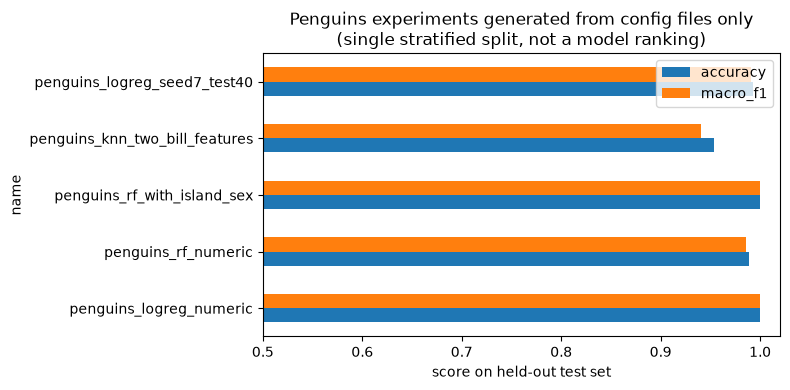

In [37]:
import matplotlib.pyplot as plt

ax = results_df[["accuracy", "macro_f1"]].plot.barh(figsize=(8, 4), xlim=(0.5, 1.02))
ax.set_title("Penguins experiments generated from config files only\n(single stratified split, not a model ranking)")
ax.set_xlabel("score on held-out test set")
plt.tight_layout()
plt.show()

> **Leitura dos resultados:** os scores vêm de uma única divisão estratificada em um dataset pequeno (344 linhas; os valores ausentes nas features são imputados dentro do pipeline); servem para demonstrar o fluxo, não para eleger o melhor modelo. O que importa é que cada linha da tabela é **reprodutível** a partir da sua pasta `config_resolved.yaml` + hash.

In [38]:
# Clean up: remove the temporary directory so nothing is left on disk
for var in ["APP_ENV", "DS_ENV", "DATASET_NAME", "TARGET_COLUMN", "RANDOM_SEED",
            "TEST_SIZE", "MAX_DEPTH", "API_TOKEN"]:
    os.environ.pop(var, None)
TMP.cleanup()
print("Temporary directory removed:", not WORKDIR.exists())

Temporary directory removed: True


---
## 📌 Resumo

### Principais aprendizados
- **Separar código e configuração** é a base da reprodutibilidade: hiperparâmetros, caminhos e seeds pertencem a arquivos versionados, não ao código.
- **INI / `configparser`** é simples, mas não tem tipos; **`os.environ`** é o canal padrão para segredos e diferenças entre ambientes; **`argparse`** fica no topo da precedência para overrides pontuais.
- **`.env` + `python-dotenv`**: ótimo para desenvolvimento local; nunca versionar o `.env`, sempre versionar o `.env.example`.
- **YAML** brilha em configs hierárquicas de ML (âncoras `&`, aliases `*`, merge `<<:`), mas exige `safe_load` e atenção à ambiguidade de tipos.
- **TOML** é explícito e lido nativamente com `tomllib` (3.11+); escrevemos com `tomli_w`. Ideal para metadados e ferramentas.
- **Composição estilo Hydra** (grupos + deep merge + overrides `a.b=valor`) gera muitos experimentos sem duplicar arquivos.
- **Pydantic** valida a config no carregamento (*fail fast*), com `extra="forbid"` capturando erros de digitação e relatórios de erro legíveis.
- No projeto aplicado, cinco experimentos com *penguins* foram produzidos **sem alterar o código**, cada um com snapshot da config e hash.

### Conexão com NLP e educação
As faixas de vocabulário "A-like / B-like / C-like" deste notebook foram derivadas da frequência no próprio Brown Corpus e configuradas em TOML — **não são níveis oficiais do CEFR**. A vantagem de colocá-las numa config é poder discutir e ajustar os limiares com professores sem reescrever o pipeline.

### Próximos passos
- Experimentar o **Hydra** real e o **OmegaConf** (interpolação `${...}`, *multirun*).
- Integrar configs com rastreamento de experimentos (MLflow) e versionamento de dados (DVC).
- Usar `pydantic-settings` para ler `.env` + variáveis de ambiente diretamente num modelo validado.